In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_harem_network.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

31

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

7.935483870967742

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  5
3  k_max:  4
5  k_max:  3
6  k_max:  2
7  k_max:  2
10  k_max:  2
11  k_max:  2


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.002155
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.012066


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 123},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 522},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 239},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 581},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 287},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 1220},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 1610},
 {'name': 'four_loop',

# Grid Search

In [11]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,5]},
                {'m': 3,  'k': [1,4]},
                {'m': 5,  'k': [1,3]},
                {'m': 6,  'k': [1,2]},
                {'m': 7,  'k': [1,2]},
                {'m': 10, 'k': [1,2]},
                {'m': 11, 'k': [1,2]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-28 13:45:31,056] A new study created in memory with name: no-name-bf78d4d1-a024-402e-9a93-dec7924132cf


Grid Search requires 4 trials...


[I 2025-01-28 13:45:45,955] Trial 0 finished with value: 7.4646299029424075 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 7.4646299029424075.
[I 2025-01-28 13:46:04,090] Trial 1 finished with value: 7.486645928377212 and parameters: {'m': 2, 'k': 4}. Best is trial 0 with value: 7.4646299029424075.
[I 2025-01-28 13:46:20,878] Trial 2 finished with value: 7.419376051995141 and parameters: {'m': 2, 'k': 2}. Best is trial 2 with value: 7.419376051995141.
[I 2025-01-28 13:46:35,837] Trial 3 finished with value: 7.35567851823347 and parameters: {'m': 2, 'k': 1}. Best is trial 3 with value: 7.35567851823347.
[I 2025-01-28 13:46:35,838] A new study created in memory with name: no-name-4e502e39-9e71-4a95-a310-948b623d3746


Grid Search requires 3 trials...


[I 2025-01-28 13:47:05,585] Trial 0 finished with value: 7.131487576705016 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 7.131487576705016.
[I 2025-01-28 13:47:39,954] Trial 1 finished with value: 6.981740423809131 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 6.981740423809131.
[I 2025-01-28 13:48:14,445] Trial 2 finished with value: 7.055670774496115 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 6.981740423809131.
[I 2025-01-28 13:48:14,447] A new study created in memory with name: no-name-b1c29e96-2c75-4405-8c53-26c9c78a9029


Grid Search requires 2 trials...


... (6 outputs left out)

[I 2025-01-28 14:03:52,899] Trial 0 finished with value: 6.502112884901614 and parameters: {'m': 10, 'k': 1}. Best is trial 0 with value: 6.502112884901614.
[I 2025-01-28 14:03:52,900] A new study created in memory with name: no-name-ee4108bb-67b5-4a2f-8926-c263ee20f852


Grid Search requires 1 trials...


[I 2025-01-28 14:14:42,910] Trial 0 finished with value: 6.431259481987219 and parameters: {'m': 11, 'k': 1}. Best is trial 0 with value: 6.431259481987219.


Best parameters:  {'m': 11, 'k': 1}
Best energy:  7.490479180120673
Best KL-divergence:  0.09705064415028178
Best KLD augumented energy: 6.431259481987219
Best P matrix:
 [[7.05115292e-01 0.00000000e+00 5.43621679e-02 5.60868287e-14
  4.26883830e-01 1.00000000e+00 1.33878684e-14 8.60562662e-01
  8.93552089e-01 4.72016850e-01 5.69305015e-13]
 [0.00000000e+00 2.09636729e-01 2.19390293e-01 3.18986788e-14
  1.72855380e-15 1.38120668e-01 1.01501120e-13 1.93072974e-13
  1.39478240e-13 0.00000000e+00 0.00000000e+00]
 [5.43621679e-02 2.19390293e-01 9.96904941e-01 9.24787587e-01
  7.06679044e-01 1.00000000e+00 8.78956716e-14 3.11543851e-01
  3.94723043e-01 1.00000000e+00 3.65456852e-01]
 [5.60868287e-14 3.18986788e-14 9.24787587e-01 2.06132297e-13
  1.67518005e-13 1.00000000e+00 0.00000000e+00 7.90327957e-13
  1.91217145e-13 3.48503866e-01 4.59248482e-01]
 [4.26883830e-01 1.72855380e-15 7.06679044e-01 1.67518005e-13
  3.44755199e-01 1.00000000e+00 1.48928810e-13 5.74385236e-02
  5.10592269e-13 

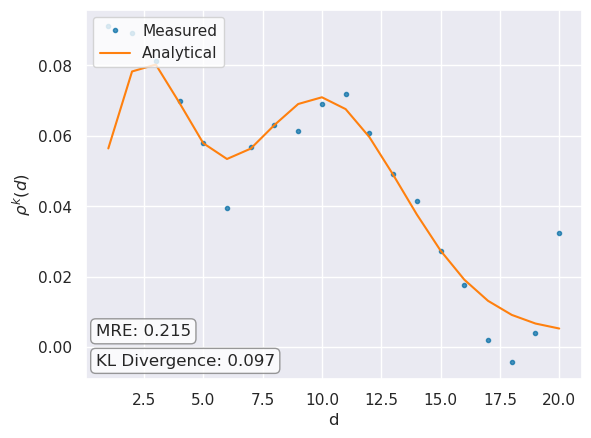

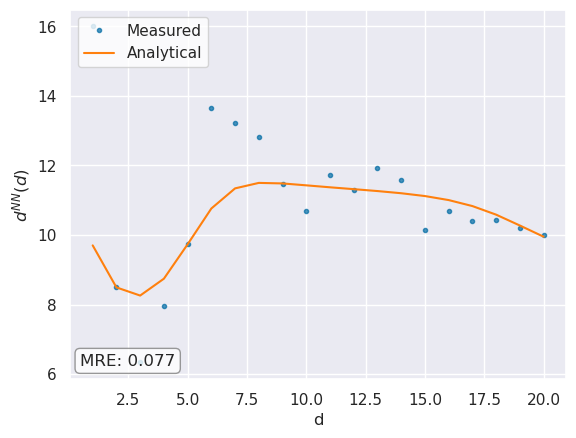

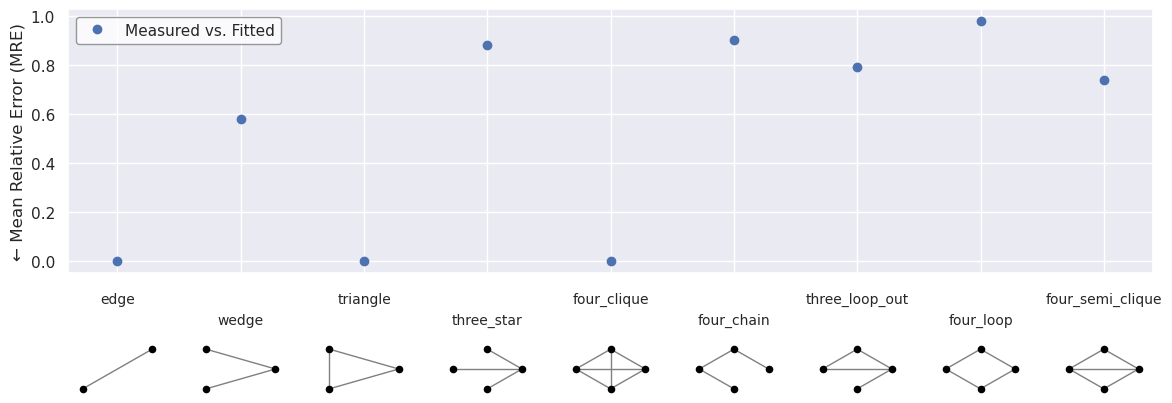

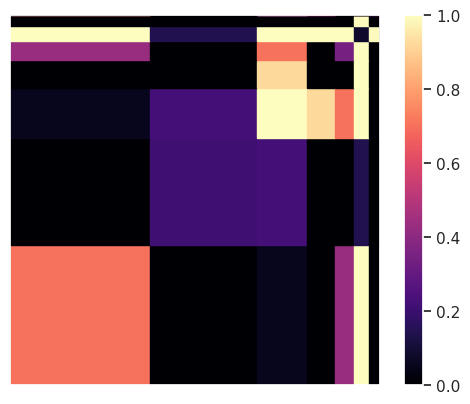

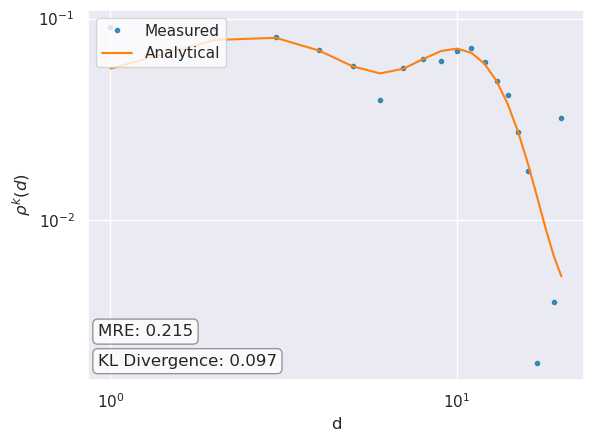

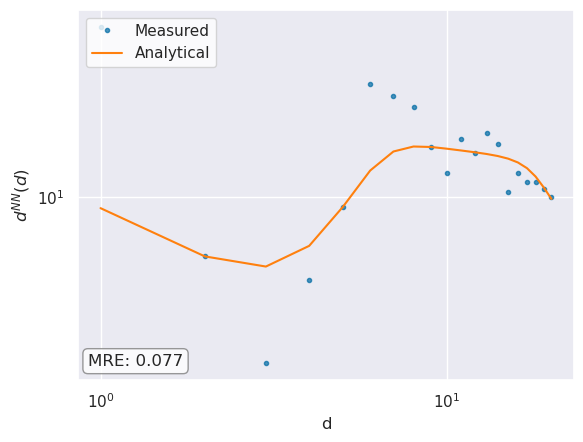

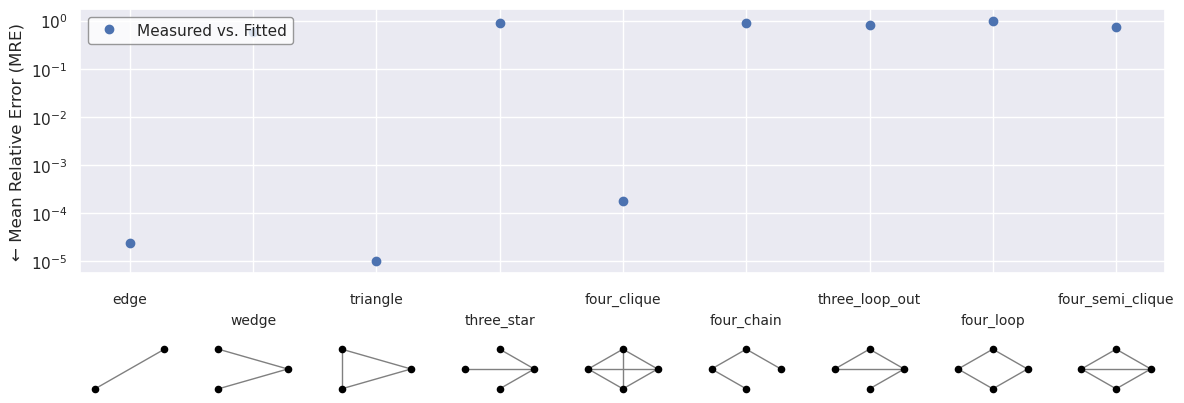

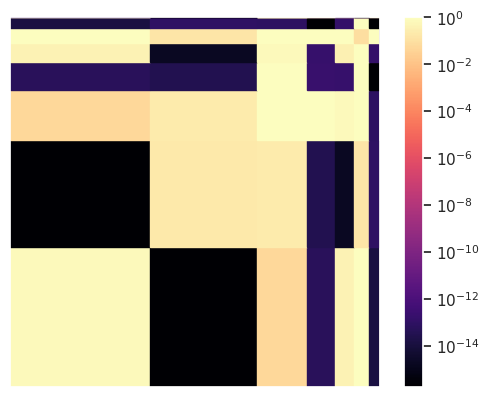

In [12]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_harem_log_plot.pdf"
)

# Bootstrapping Stability

In [10]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Energy: 7.484216153717247
KL-divergence: 0.09559908245712484
KLD augumented energy: 6.427902090823373
Gathering statistics (30 runs)...


100%|██████████| 30/30 [5:43:12<00:00, 686.40s/it]  

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.218045
Energy = 7.49 (7.47, 7.51)
l = [0.35 (0.27, 0.42), 0.25 (0.16, 0.33), 0.15 (0.08, 0.23), 0.09 (0.04, 0.17), 0.05 (0.03, 0.10), 0.04 (0.02, 0.06), 0.03 (0.01, 0.04), 0.02 (0.00, 0.04), 0.00 (0.00, 0.03), 0.00 (0.00, 0.02), 0.00 (0.00, 0.00)]
P = [
[0.70 (0.17, 0.83), 0.00 (0.00, 0.22), 0.14 (0.00, 0.28), 0.00 (0.00, 0.44), 0.08 (0.00, 1.00), 0.22 (0.00, 1.00), 0.00 (0.00, 1.00), 0.11 (0.00, 1.00), 0.01 (0.00, 1.00), 0.28 (0.00, 1.00), 0.25 (0.00, 1.00)],

[0.00 (0.00, 0.22), 0.32 (0.17, 1.00), 0.00 (0.00, 0.52), 0.00 (0.00, 0.88), 0.02 (0.00, 0.84), 0.09 (0.00, 1.00), 0.01 (0.00, 1.00), 0.00 (0.00, 0.98), 0.01 (0.00, 0.85), 0.04 (0.00, 0.98), 0.01 (0.00, 0.92)],

[0.14 (0.00, 0.28), 0.00 (0.00, 0.52), 0.92 (0.00, 1.00), 0.42 (0.00, 1.00), 0.79 (0.00, 1.00), 0.98 (0.00, 1.00), 0.03 (0.00, 1.00), 0.57 (0.00, 1.00), 0.06 (0.00, 0.99), 0.05 (0.00, 1.00), 0.11 (0.00, 1.00)],

[0.00 (0.00, 0.44), 0.00 (0.00, 0.88), 0.42 (0.00, 1.00), 0.23 (0.00, 1.00),

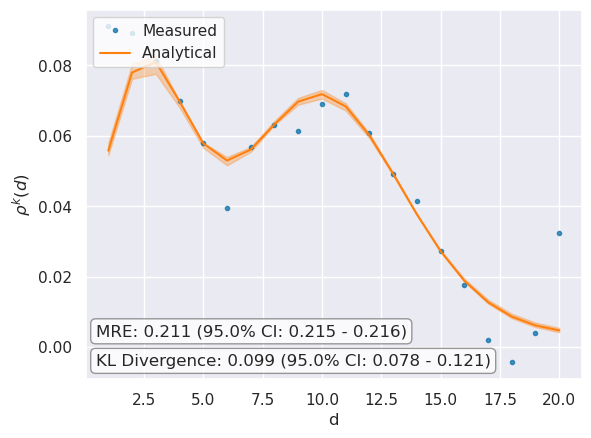

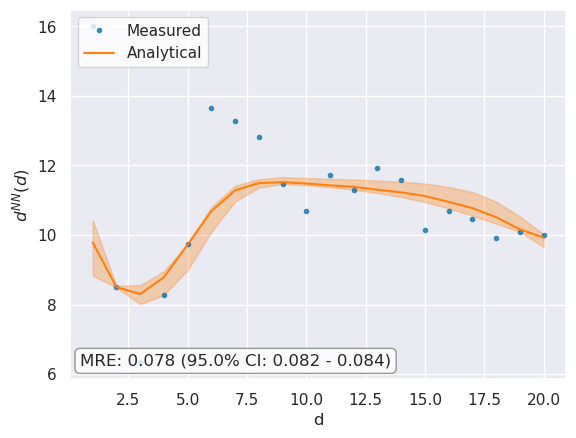

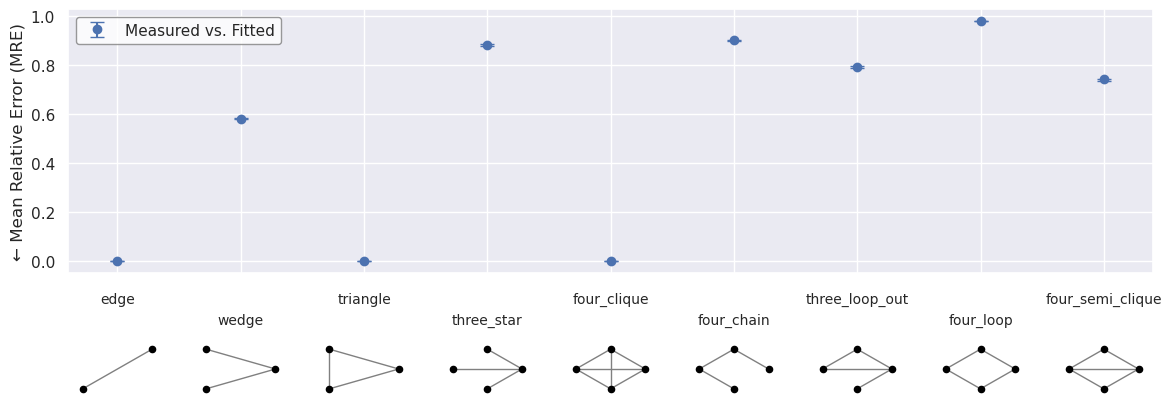

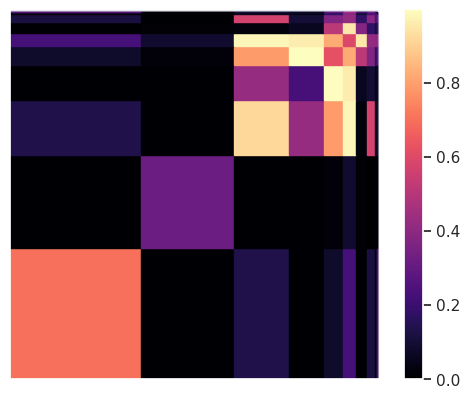

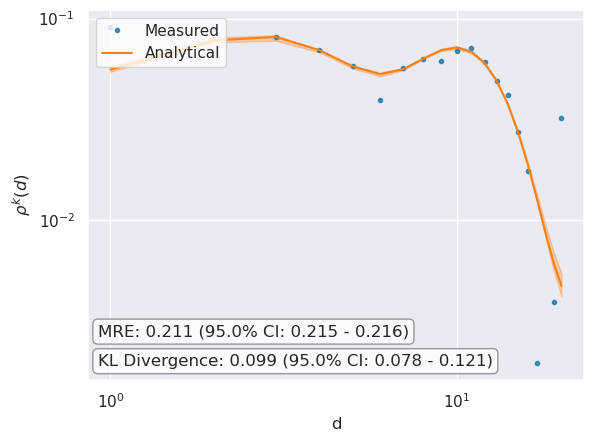

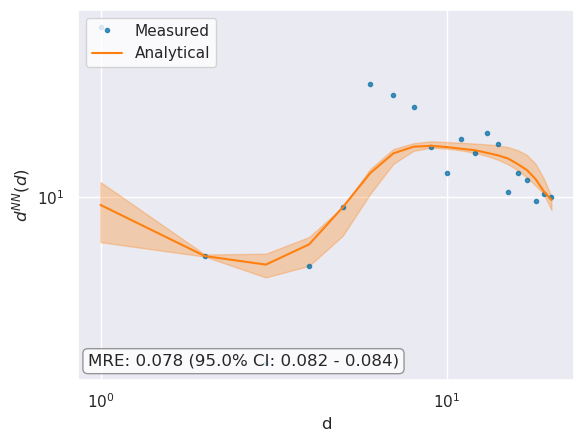

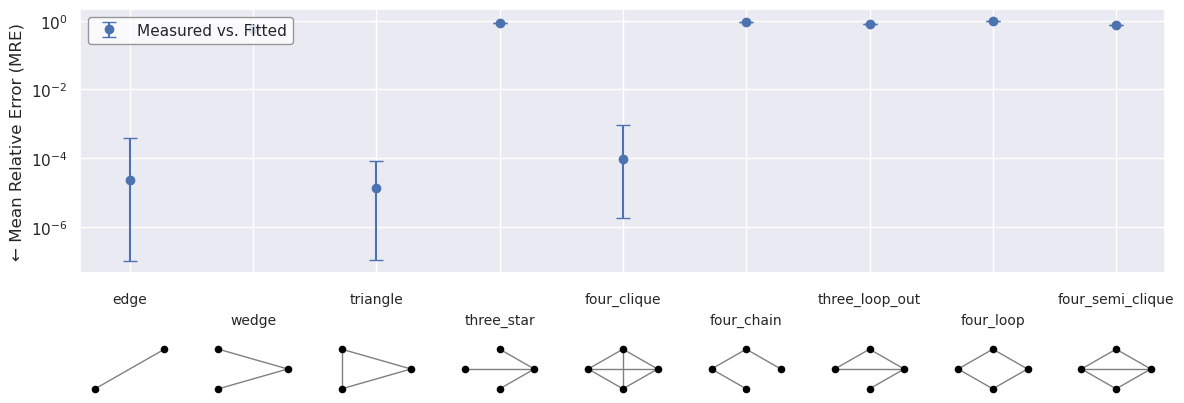

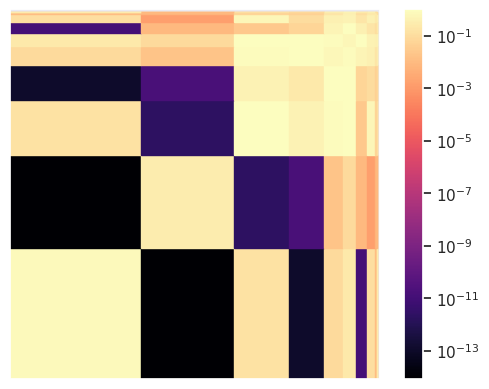

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_harem_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_harem_log_plot.pdf"
)

# Generate Variants

Initializing...
0.00019431114196777344
Calculating betweenness...
Done.
Calculating node positions...
Done.


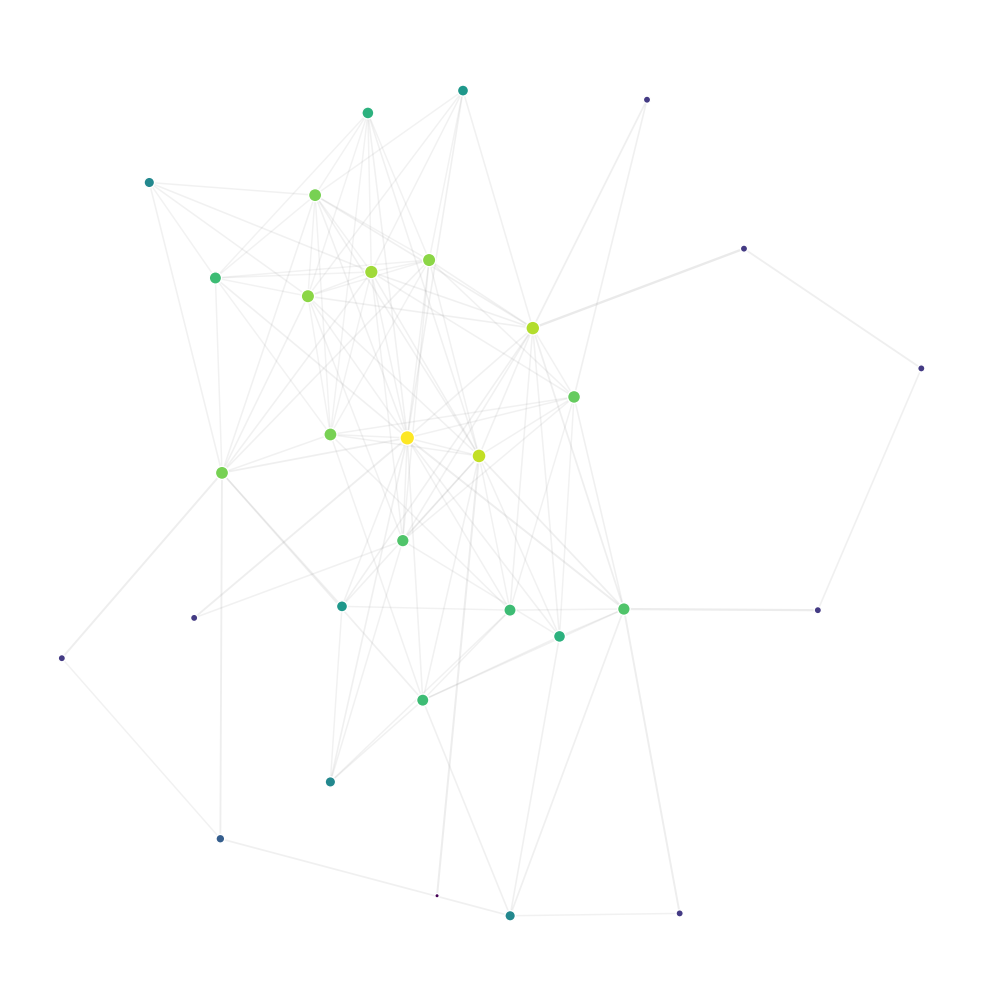

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 4471.54it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


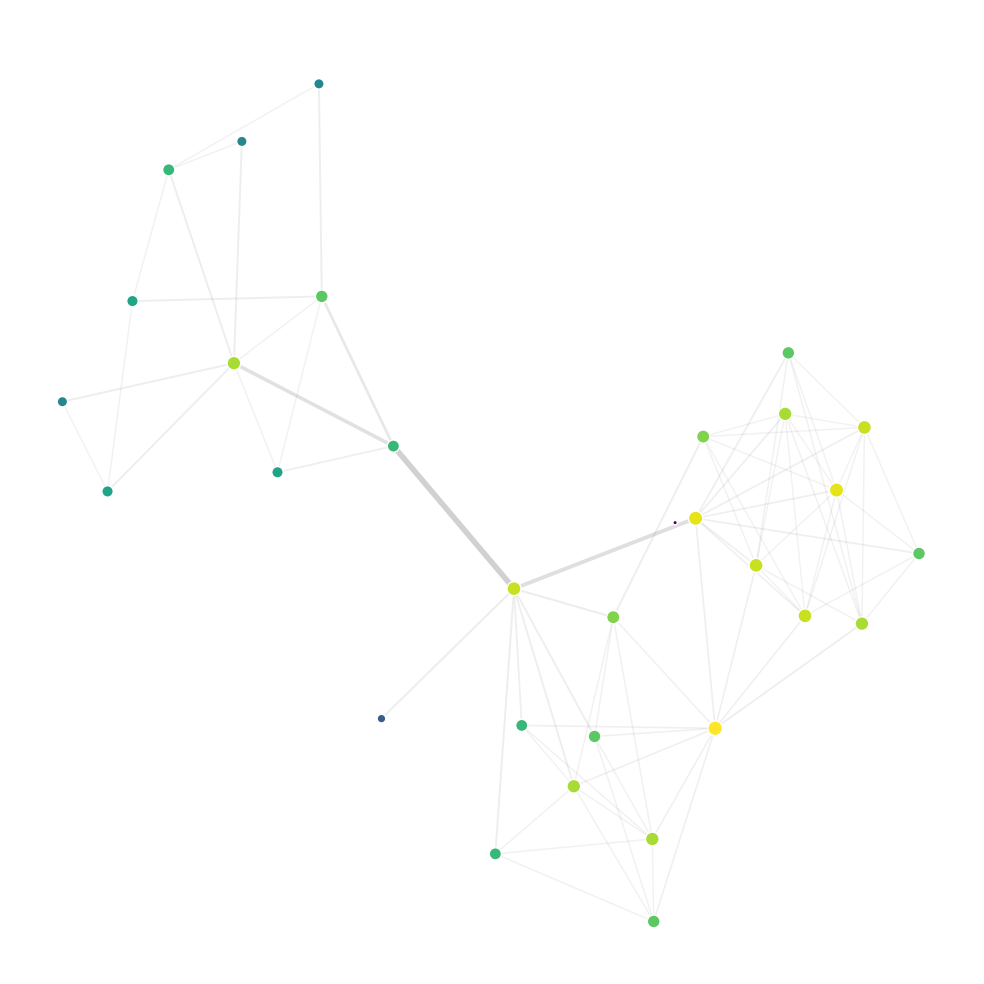

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 6080.90it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


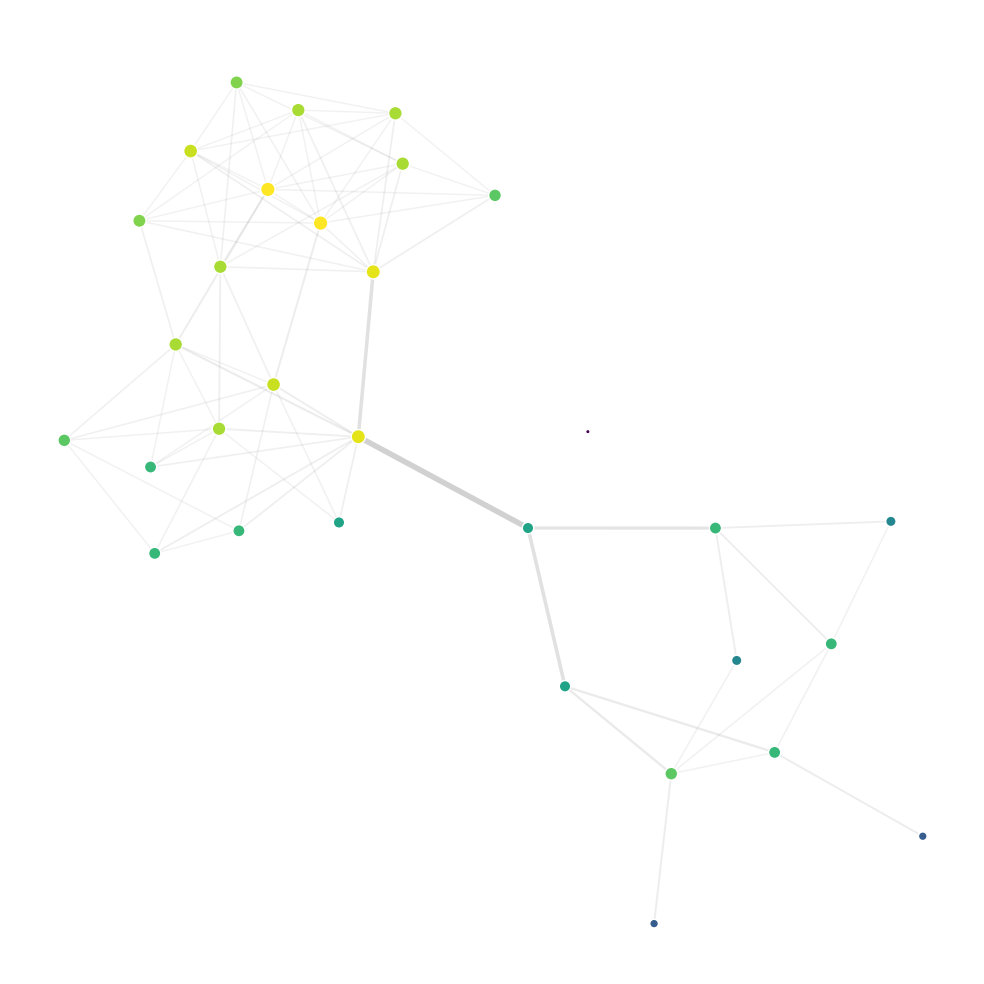

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 4809.64it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


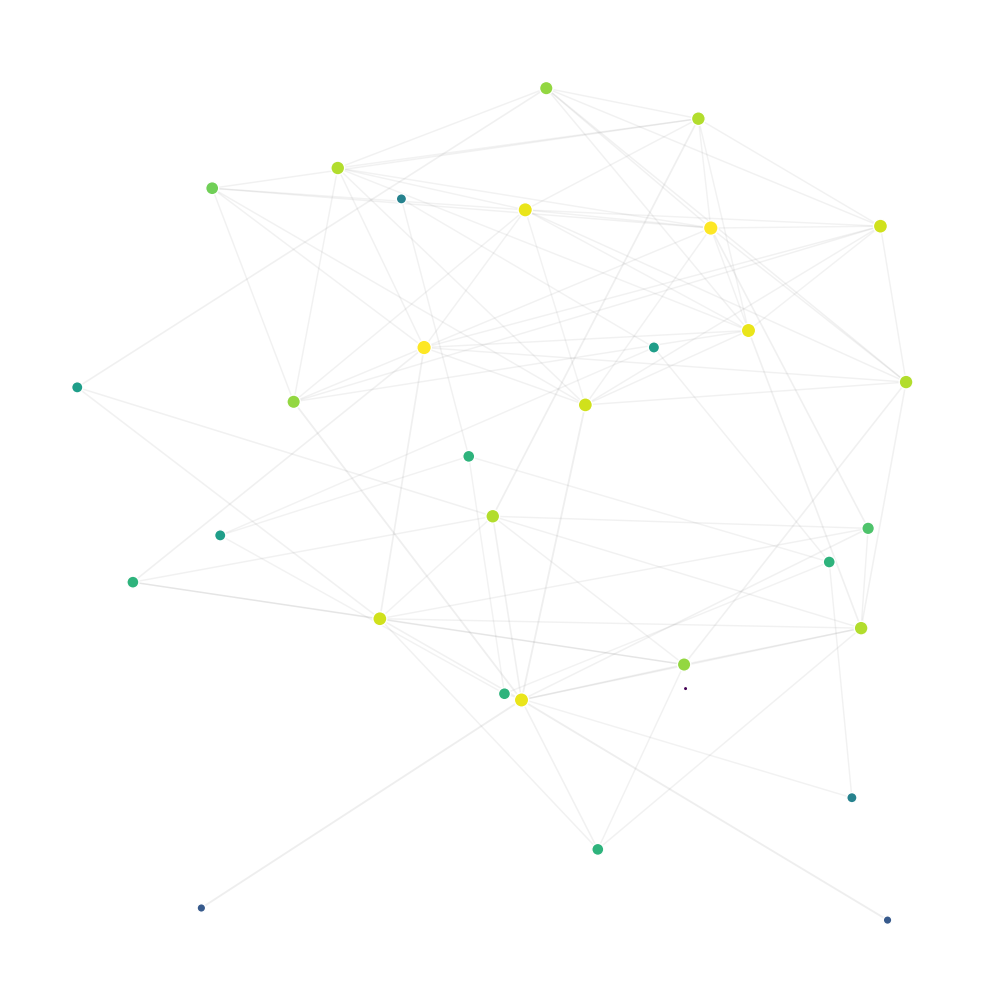

In [12]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_harem_variants.pdf"
    },
    filename = "variant_networks/horses_harem_variants.graphml"
)